In [ ]:
%%capture
%%bash
# 1. Instalar espeak-ng en el sistema operativo para convertir texto en fonemas
apt-get update -qq && apt-get install -y -qq espeak-ng > /dev/null 2>&1

# 2. Clonar el repositorio oficial de StyleTTS 2
git clone -q https://github.com/yl4579/StyleTTS2.git
cd StyleTTS2

# 3. Instalar las librerías de Python necesarias (silenciando los mensajes de pip)
pip install -q SoundFile torchaudio munch pydub pyyaml librosa nltk matplotlib accelerate transformers einops einops-exts tqdm typing-extensions git+https://github.com/resemble-ai/monotonic_align.git phonemizer > /dev/null 2>&1

# 4. Crear carpeta y descargar los pesos preentrenados multispeaker (LibriTTS) desde HuggingFace
mkdir -p Models/LibriTTS
wget -q https://huggingface.co/yl4579/StyleTTS2-LibriTTS/resolve/main/Models/LibriTTS/epochs_2nd_00020.pth -O Models/LibriTTS/epochs_2nd_00020.pth
wget -q https://huggingface.co/yl4579/StyleTTS2-LibriTTS/resolve/main/Models/LibriTTS/config.yml -O Models/LibriTTS/config.yml

In [ ]:
import glob
import os
import pandas as pd
from sklearn.model_selection import StratifiedShuffleSplit

# 1. Localizar speaker-info.txt en /kaggle/input
vctk_files = glob.glob("/kaggle/input/**/speaker-info.txt", recursive=True)
assert len(vctk_files) > 0, "No se encontró speaker-info.txt."
vctk_root = os.path.dirname(vctk_files[0])

# 2. Parsear speaker-info.txt línea a línea (evita errores por espacios en la columna REGION)
rows = []
with open(vctk_files[0], "r", encoding="utf-8") as f:
    for line in f.readlines()[1:]:  # saltar cabecera
        parts = line.strip().split()
        if len(parts) >= 4:
            raw_id = parts[0]
            spk_id = raw_id if raw_id.startswith("p") else f"p{raw_id}"
            rows.append({
                "ID": spk_id,
                "AGE": parts[1],
                "GENDER": parts[2],
                "ACCENTS": parts[3],
            })

df_spk = pd.DataFrame(rows)
df_spk["AGE"] = pd.to_numeric(df_spk["AGE"], errors="coerce")
df_spk = df_spk.dropna(subset=["AGE", "GENDER"]).reset_index(drop=True)

# 3. Localizar la carpeta base de AUDIOS (.wav o .flac), evitando la carpeta 'txt'
audio_candidates = [
    os.path.dirname(p)
    for p in glob.glob(f"{vctk_root}/**/p225/*.*", recursive=True)
    if p.lower().endswith((".wav", ".flac")) and "/txt/" not in p.lower()
]
assert len(audio_candidates) > 0, (
    f"No se encontraron archivos de audio dentro de {vctk_root}"
)

audio_base = os.path.dirname(audio_candidates[0])
print(f"Carpeta de audios detectada: {audio_base}")

# 4. Filtrar solo locutores que realmente tengan carpeta con audios
available_spks = {
    d
    for d in os.listdir(audio_base)
    if os.path.isdir(os.path.join(audio_base, d))
    and len(glob.glob(os.path.join(audio_base, d, "*.*"))) > 0
}
df_spk = df_spk[df_spk["ID"].isin(available_spks)].reset_index(drop=True)
assert len(df_spk) > 0, "0 locutores tras filtrar."

# 5. Partición estratificada 80% train / 20% test disjunta por locutor
splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
for train_idx, test_idx in splitter.split(df_spk, df_spk["GENDER"]):
    df_spk["split"] = "train"
    df_spk.loc[test_idx, "split"] = "test"

# 6. Guardar el CSV con la división
os.makedirs("/kaggle/working/data_splits", exist_ok=True)
df_spk.to_csv("/kaggle/working/data_splits/vctk_speakers_split.csv", index=False)

print(f"VCTK listo. Total locutores válidos: {len(df_spk)}")
print(df_spk.groupby(["split", "GENDER"])["AGE"].agg(["count", "mean", "std"]))

In [ ]:
%%capture
import sys
sys.path.append('/kaggle/working/StyleTTS2')

import torch

# Parche de compatibilidad para PyTorch 2.6+ (permite cargar los checkpoints antiguos de StyleTTS 2)
_orig_torch_load = torch.load
def _patched_torch_load(*args, **kwargs):
    kwargs.setdefault('weights_only', False)
    return _orig_torch_load(*args, **kwargs)
torch.load = _patched_torch_load

import torchaudio
import librosa
import yaml
import phonemizer
import numpy as np
import soundfile as sf
from collections import OrderedDict
import nltk
from nltk.tokenize import word_tokenize
from models import *
from utils import *
from text_utils import TextCleaner
from Utils.PLBERT.util import load_plbert

# Descargar tokenizador de frases
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

# Seleccionar GPU si está disponible
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# 1. Cargar el archivo de configuración del modelo
config_path = "/kaggle/working/StyleTTS2/Models/LibriTTS/config.yml"
model_path = "/kaggle/working/StyleTTS2/Models/LibriTTS/epochs_2nd_00020.pth"
config = yaml.safe_load(open(config_path))

# 2. Cargar los módulos auxiliares preentrenados (alineador de texto, extractor de tono F0 y PL-BERT)
text_aligner = load_ASR_models(f"/kaggle/working/StyleTTS2/{config['ASR_path']}", f"/kaggle/working/StyleTTS2/{config['ASR_config']}")
pitch_extractor = load_F0_models(f"/kaggle/working/StyleTTS2/{config['F0_path']}")
plbert = load_plbert(f"/kaggle/working/StyleTTS2/{config['PLBERT_dir']}")

# 3. Construir la arquitectura principal de StyleTTS 2 y pasarla a GPU en modo evaluación
model_params = recursive_munch(config['model_params'])
model = build_model(model_params, text_aligner, pitch_extractor, plbert)
_ = [model[key].eval() for key in model]
_ = [model[key].to(device) for key in model]

# 4. Cargar los pesos entrenados en cada sub-red del modelo
params_whole = torch.load(model_path, map_location='cpu')
params = params_whole['net']
for key in model:
    if key in params:
        try:
            model[key].load_state_dict(params[key])
        except:
            # Limpiar prefijo 'module.' si el modelo se entrenó en multi-GPU
            new_state_dict = OrderedDict((k[7:], v) for k, v in params[key].items())
            model[key].load_state_dict(new_state_dict, strict=False)
_ = [model[key].eval() for key in model]

# 5. Inicializar transformador a espectrograma Mel y fonemizador en inglés
to_mel = torchaudio.transforms.MelSpectrogram(n_mels=80, n_fft=2048, win_length=1200, hop_length=300)
mean, std = -4, 4
global_phonemizer = phonemizer.backend.EspeakBackend(language='en-us', preserve_punctuation=True, with_stress=True)
textclenaer = TextCleaner()

def preprocess(wave):
    """Convierte la onda de audio en un espectrograma Mel normalizado."""
    wave_tensor = torch.from_numpy(wave).float()
    mel_tensor = to_mel(wave_tensor)
    return (torch.log(1e-5 + mel_tensor.unsqueeze(0)) - mean) / std

@torch.no_grad()
def extract_style_vector(wav_path):
    """Extrae el vector latente z de 256 dimensiones (128 acústicas + 128 prosódicas) de un audio."""
    wave, sr = librosa.load(wav_path, sr=24000)
    audio, _ = librosa.effects.trim(wave, top_db=30)  # Recortar silencios al inicio y final
    mel_tensor = preprocess(audio).to(device)
    
    # Extraer mitad acústica (timbre) y mitad prosódica (ritmo/entonación)
    ref_s = model.style_encoder(mel_tensor.unsqueeze(1))
    ref_p = model.predictor_encoder(mel_tensor.unsqueeze(1))
    
    # Concatenar ambos en un único vector z de 256 dimensiones
    z = torch.cat([ref_s, ref_p], dim=1)
    return z.squeeze(0).cpu().numpy()

@torch.no_grad()
def synthesize_from_z(text, z_np):
    """Genera una onda de audio a partir de un texto y un vector latente z modificado."""
    # Convertir texto a fonemas y tokens numéricos
    ps = global_phonemizer.phonemize([text.strip()])
    ps = " ".join(word_tokenize(ps[0]))
    tokens = textclenaer(ps)
    tokens.insert(0, 0)
    tokens = torch.LongTensor(tokens).to(device).unsqueeze(0)
    
    # Preparar nuestro vector z como entrada de condicionamiento
    ref_s = torch.from_numpy(z_np).float().to(device).unsqueeze(0)
    input_lengths = torch.LongTensor([tokens.shape[-1]]).to(tokens.device)
    text_mask = length_to_mask(input_lengths).to(tokens.device)

    # Codificar texto y extraer características lingüísticas con PL-BERT
    t_en = model.text_encoder(tokens, input_lengths, text_mask)
    bert_dur = model.bert(tokens, attention_mask=(~text_mask).int())
    d_en = model.bert_encoder(bert_dur).transpose(-1, -2) 

    # Separar el vector z en su mitad prosódica (128:) y acústica (:128)
    s = ref_s[:, 128:]
    ref = ref_s[:, :128]

    # Predecir duración de cada fonema y alinear texto con audio
    d = model.predictor.text_encoder(d_en, s, input_lengths, text_mask)
    x, _ = model.predictor.lstm(d)
    duration = torch.sigmoid(model.predictor.duration_proj(x)).sum(axis=-1)
    pred_dur = torch.round(duration.squeeze()).clamp(min=1)

    pred_aln_trg = torch.zeros(int(input_lengths.item()), int(pred_dur.sum().data))
    c_frame = 0
    for i in range(pred_aln_trg.size(0)):
        pred_aln_trg[i, c_frame:c_frame + int(pred_dur[i].data)] = 1
        c_frame += int(pred_dur[i].data)

    # Predecir contorno de tono (F0) y energía, y sintetizar la forma de onda final
    en = (d.transpose(-1, -2) @ pred_aln_trg.unsqueeze(0).to(device))
    F0_pred, N_pred = model.predictor.F0Ntrain(en, s)
    asr = (t_en @ pred_aln_trg.unsqueeze(0).to(device))
    out = model.decoder(asr, F0_pred, N_pred, ref.squeeze().unsqueeze(0))
    
    return out.squeeze().cpu().numpy()[..., :-50]

In [ ]:
import IPython.display as ipd

# 1. Crear carpeta de salida para los audios de prueba
out_dir = "/kaggle/working/hito_viabilidad_audios"
os.makedirs(out_dir, exist_ok=True)
df_spk = pd.read_csv("/kaggle/working/data_splits/vctk_speakers_split.csv")

# 2. Seleccionar una locutora (F) y un locutor (M) del conjunto de TEST
spk_f = df_spk[(df_spk["split"] == "test") & (df_spk["GENDER"] == "F")].iloc[0][
    "ID"
]
spk_m = df_spk[(df_spk["split"] == "test") & (df_spk["GENDER"] == "M")].iloc[0][
    "ID"
]

# 3. Extraer y promediar los vectores z de 5 audios de cada uno para obtener una representación limpia
wavs_f = sorted(glob.glob(f"{audio_base}/{spk_f}/*.*"))[:5]
wavs_m = sorted(glob.glob(f"{audio_base}/{spk_m}/*.*"))[:5]

z_f = np.mean([extract_style_vector(w) for w in wavs_f], axis=0)
z_m = np.mean([extract_style_vector(w) for w in wavs_m], axis=0)

test_sentence = "Interpretable control of vocal identity allows designing new synthetic voices without cloning real individuals."

# 4. Generar y guardar las voces base originales reconstruidas
sf.write(
    f"{out_dir}/1_base_{spk_f}_F.wav",
    synthesize_from_z(test_sentence, z_f),
    24000,
)
sf.write(
    f"{out_dir}/2_base_{spk_m}_M.wav",
    synthesize_from_z(test_sentence, z_m),
    24000,
)

# 5. Generar y guardar una interpolación lineal al 50% entre ambas voces
z_interp = 0.5 * z_f + 0.5 * z_m
sf.write(
    f"{out_dir}/3_interpolacion_50_50.wav",
    synthesize_from_z(test_sentence, z_interp),
    24000,
)

# 6. Desplazar progresivamente la voz femenina hacia la masculina (alpha = 0.5, 1.0, 1.5)
d_vec = z_m - z_f
for alpha in [0.5, 1.0, 1.5]:
    z_shifted = z_f + alpha * d_vec
    sf.write(
        f"{out_dir}/4_desplazamiento_alpha_{alpha}.wav",
        synthesize_from_z(test_sentence, z_shifted),
        24000,
    )

print(
    f"Hito de viabilidad completado con éxito. Audios guardados en: {out_dir}"
)
# Mostrar reproductor directo de la interpolación para verificar que suena bien
ipd.display(ipd.Audio(f"{out_dir}/3_interpolacion_50_50.wav", rate=24000))

In [ ]:
import shutil

# Comprimir la carpeta de audios en un archivo .zip dentro de /kaggle/working
zip_path = shutil.make_archive(
    "/kaggle/working/hito_viabilidad_audios",
    "zip",
    "/kaggle/working/hito_viabilidad_audios",
)
print(f"ZIP creado en: {zip_path}")

In [11]:
import glob
import os
import numpy as np
import pandas as pd
from tqdm import tqdm

# 1. Cargar la tabla de locutores con la partición train/test ya generada
df_spk = pd.read_csv("/kaggle/working/data_splits/vctk_speakers_split.csv")

# Asegurar que tenemos audio_base definido (por si reiniciaste sesión)
if "audio_base" not in globals():
    vctk_root = os.path.dirname(
        glob.glob("/kaggle/input/**/speaker-info.txt", recursive=True)[0]
    )
    audio_candidates = [
        os.path.dirname(p)
        for p in glob.glob(f"{vctk_root}/**/p225/*.*", recursive=True)
        if p.lower().endswith((".wav", ".flac")) and "/txt/" not in p.lower()
    ]
    audio_base = os.path.dirname(audio_candidates[0])

MAX_WAVS_PER_SPK = 20  # Máximo de audios por locutor para equilibrar precisión y tiempo en GPU

spk_vectors = []
valid_rows = []

# 2. Extraer y promediar el vector z por cada locutor
for _, row in tqdm(
    df_spk.iterrows(), total=len(df_spk), desc="Extrayendo vectores por locutor"
):
    spk_id = row["ID"]
    wav_files = sorted(glob.glob(os.path.join(audio_base, spk_id, "*.*")))
    wav_files = [
        w for w in wav_files if w.lower().endswith((".wav", ".flac"))
    ][:MAX_WAVS_PER_SPK]

    if len(wav_files) == 0:
        continue

    zs = []
    for w in wav_files:
        try:
            zs.append(extract_style_vector(w))
        except Exception:
            # Omitir algún archivo corrupto si existiera
            continue

    if len(zs) > 0:
        # Promedio por locutor para reducir variabilidad de frase y prosodia puntual
        z_mean = np.mean(np.stack(zs, axis=0), axis=0)
        spk_vectors.append(z_mean)
        valid_rows.append(row.to_dict())

Z_spk = np.stack(spk_vectors, axis=0)  # Forma: [N_locutores, 256]
df_valid = pd.DataFrame(valid_rows).reset_index(drop=True)

# 3. Guardar vectores y metadatos alineados en disco
out_npz = "/kaggle/working/vctk_speaker_vectors.npz"
np.savez(
    out_npz,
    Z=Z_spk,
    ids=df_valid["ID"].values,
    genders=df_valid["GENDER"].values,
    ages=df_valid["AGE"].values,
    accents=df_valid["ACCENTS"].values,
    splits=df_valid["split"].values,
)
df_valid.to_csv(
    "/kaggle/working/data_splits/vctk_speakers_valid.csv", index=False
)

print(
    f"Extracción finalizada. Matriz Z: {Z_spk.shape} guardada en {out_npz}"
)

Extrayendo vectores por locutor: 100%|██████████| 108/108 [00:59<00:00,  1.80it/s]

Extracción finalizada. Matriz Z: (108, 256) guardada en /kaggle/working/vctk_speaker_vectors.npz


In [12]:
import numpy as np
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    mean_absolute_error,
    r2_score,
)
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler

# 1. Cargar vectores y metadatos por locutor
data = np.load("/kaggle/working/vctk_speaker_vectors.npz", allow_pickle=True)
Z_all = data["Z"]
ids_all = data["ids"]
genders_all = data["genders"]
ages_all = data["ages"].astype(float)
splits_all = data["splits"]

# Trabajamos sobre la partición de entrenamiento (disjunta respecto a test)
train_mask = splits_all == "train"
Z_tr = Z_all[train_mask]
ids_tr = ids_all[train_mask]
genders_tr = (genders_all[train_mask] == "F").astype(
    int
)  # 1 = F, 0 = M (o codificación binaria clara)
ages_tr = ages_all[train_mask]

# Subespacios del vector z (256 dims): completo, acústico [:128] y prosódico [128:]
subspaces = {
    "Completo (256d)": Z_tr,
    "Acústico (:128d)": Z_tr[:, :128],
    "Prosódico (128d:)": Z_tr[:, 128:],
}

n_splits = 5

print("=== SONDA LINEAL DE GÉNERO (Clasificación - Validación Cruzada por Locutor) ===")
sgkf = StratifiedGroupKFold(n_splits=n_splits)
for name, X in subspaces.items():
    accs, f1s = [], []
    for tr_idx, val_idx in sgkf.split(X, genders_tr, groups=ids_tr):
        scaler = StandardScaler()
        X_train_s = scaler.fit_transform(X[tr_idx])
        X_val_s = scaler.transform(X[val_idx])

        clf = LogisticRegression(max_iter=1000, C=1.0, random_state=42)
        clf.fit(X_train_s, genders_tr[tr_idx])
        preds = clf.predict(X_val_s)

        accs.append(accuracy_score(genders_tr[val_idx], preds))
        f1s.append(f1_score(genders_tr[val_idx], preds, zero_division=0))

    print(
        f"{name:20s} | Acc: {np.mean(accs):.4f} ± {np.std(accs):.4f} | F1: {np.mean(f1s):.4f} ± {np.std(f1s):.4f}"
    )

print(
    "\n=== SONDA LINEAL DE EDAD (Regresión Ridge - Validación Cruzada por Locutor) ==="
)
gkf = GroupKFold(n_splits=n_splits)
for name, X in subspaces.items():
    maes, r2s = [], []
    for tr_idx, val_idx in gkf.split(X, ages_tr, groups=ids_tr):
        scaler = StandardScaler()
        X_train_s = scaler.fit_transform(X[tr_idx])
        X_val_s = scaler.transform(X[val_idx])

        reg = Ridge(alpha=10.0, random_state=42)
        reg.fit(X_train_s, ages_tr[tr_idx])
        preds = reg.predict(X_val_s)

        maes.append(mean_absolute_error(ages_tr[val_idx], preds))
        r2s.append(r2_score(ages_tr[val_idx], preds))

    print(
        f"{name:20s} | MAE: {np.mean(maes):.2f} ± {np.std(maes):.2f} años | R2: {np.mean(r2s):.4f} ± {np.std(r2s):.4f}"
    )

=== SONDA LINEAL DE GÉNERO (Clasificación - Validación Cruzada por Locutor) ===
Completo (256d)      | Acc: 1.0000 ± 0.0000 | F1: 1.0000 ± 0.0000
Acústico (:128d)     | Acc: 1.0000 ± 0.0000 | F1: 1.0000 ± 0.0000
Prosódico (128d:)    | Acc: 1.0000 ± 0.0000 | F1: 1.0000 ± 0.0000

=== SONDA LINEAL DE EDAD (Regresión Ridge - Validación Cruzada por Locutor) ===
Completo (256d)      | MAE: 2.90 ± 0.13 años | R2: -0.7655 ± 0.3524
Acústico (:128d)     | MAE: 2.83 ± 0.30 años | R2: -0.9171 ± 0.2363
Prosódico (128d:)    | MAE: 2.54 ± 0.23 años | R2: -0.5825 ± 0.5042


=== SIMILITUD COSENO ENTRE DIRECCIONES (ANTES DE ORTOGONALIZAR) ===
[[ 1.      0.0667 -0.0143]
 [ 0.0667  1.      0.0041]
 [-0.0143  0.0041  1.    ]]

=== SIMILITUD COSENO ENTRE DIRECCIONES (DESPUÉS DE ORTOGONALIZAR) ===
[[ 1.  0. -0.]
 [ 0.  1.  0.]
 [-0.  0.  1.]]


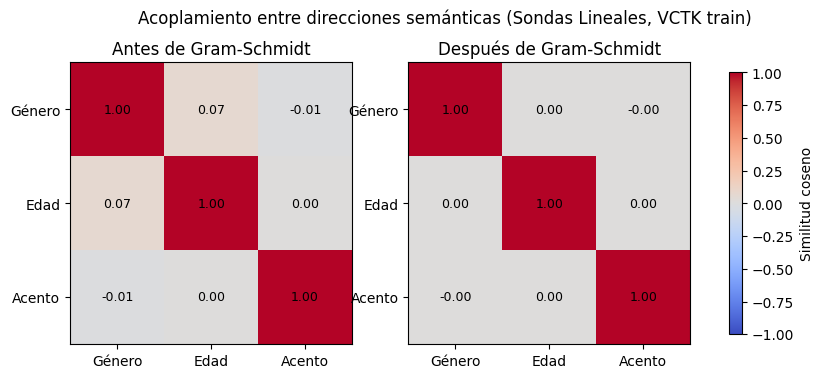

In [13]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import LabelEncoder, StandardScaler

# 1. Cargar matriz de vectores por locutor y metadatos
data = np.load("/kaggle/working/vctk_speaker_vectors.npz", allow_pickle=True)
Z_all = data["Z"]
genders_all = data["genders"]
ages_all = data["ages"].astype(float)
accents_all = data["accents"].astype(str)
splits_all = data["splits"]

# Usar únicamente la partición de entrenamiento para estimar direcciones (evita fuga de datos)
train_mask = splits_all == "train"
Z_tr = Z_all[train_mask]
y_gender = (genders_all[train_mask] == "F").astype(float)
y_age = ages_all[train_mask]
y_accent = LabelEncoder().fit_transform(accents_all[train_mask]).astype(float)


def unit_vec(v):
    """Normaliza un vector a norma unidad de forma segura."""
    norm = np.linalg.norm(v)
    return v / norm if norm > 1e-12 else v


def gram_schmidt_orthogonalize(target_vec, basis_vecs):
    """Proyecta target_vec ortogonalmente respecto a una lista de vectores base."""
    v = target_vec.copy()
    for b in basis_vecs:
        b_unit = unit_vec(b)
        v = v - np.dot(v, b_unit) * b_unit
    return unit_vec(v)


# 2. Estimación por Línea Base: PCA (primer componente principal sobre Z_tr)
pca = PCA(n_components=3, random_state=42)
pca.fit(Z_tr)
d_pca_1 = unit_vec(pca.components_[0])

# 3. Estimación por Diferencia de Centroides (Género y Edad dicotomizada por mediana)
z_f_mean = Z_tr[y_gender == 1].mean(axis=0)
z_m_mean = Z_tr[y_gender == 0].mean(axis=0)
d_diff_gender = unit_vec(z_f_mean - z_m_mean)

age_med = np.median(y_age)
d_diff_age = unit_vec(
    Z_tr[y_age >= age_med].mean(axis=0) - Z_tr[y_age < age_med].mean(axis=0)
)

# 4. Estimación por Sondas Lineales (pesos normalizados en el espacio original)
scaler = StandardScaler()
Z_tr_s = scaler.fit_transform(Z_tr)

clf_gen = LogisticRegression(max_iter=1000, C=1.0, random_state=42).fit(
    Z_tr_s, y_gender
)
reg_age = Ridge(alpha=10.0, random_state=42).fit(Z_tr_s, y_age)
reg_acc = Ridge(alpha=10.0, random_state=42).fit(Z_tr_s, y_accent)

# Devolver pesos al espacio latente original (dividiendo por la escala de cada dimensión)
d_probe_gender = unit_vec(clf_gen.coef_.ravel() / scaler.scale_)
d_probe_age = unit_vec(reg_age.coef_.ravel() / scaler.scale_)
d_probe_accent = unit_vec(reg_acc.coef_.ravel() / scaler.scale_)

# 5. Ortogonalización de Gram-Schmidt sobre las direcciones de sondas lineales:
#    - Género se mantiene como referencia principal
#    - Edad se ortogonaliza respecto a Género
#    - Acento se ortogonaliza respecto a Género y Edad
d_orth_gender = unit_vec(d_probe_gender)
d_orth_age = gram_schmidt_orthogonalize(d_probe_age, [d_orth_gender])
d_orth_accent = gram_schmidt_orthogonalize(
    d_probe_accent, [d_orth_gender, d_orth_age]
)

# 6. Calcular similitud coseno ANTES y DESPUÉS de ortogonalizar
names = ["Género", "Edad", "Acento"]
before_vecs = np.stack([d_probe_gender, d_probe_age, d_probe_accent])
after_vecs = np.stack([d_orth_gender, d_orth_age, d_orth_accent])

sim_before = cosine_similarity(before_vecs)
sim_after = cosine_similarity(after_vecs)

print("=== SIMILITUD COSENO ENTRE DIRECCIONES (ANTES DE ORTOGONALIZAR) ===")
print(np.round(sim_before, 4))

print("\n=== SIMILITUD COSENO ENTRE DIRECCIONES (DESPUÉS DE ORTOGONALIZAR) ===")
print(np.round(sim_after, 4))

# 7. Guardar direcciones y figura comparativa
os.makedirs("/kaggle/working/resultados_bloque3", exist_ok=True)
np.savez(
    "/kaggle/working/resultados_bloque3/direcciones_semánticas.npz",
    d_pca_1=d_pca_1,
    d_diff_gender=d_diff_gender,
    d_diff_age=d_diff_age,
    d_probe_gender=d_probe_gender,
    d_probe_age=d_probe_age,
    d_probe_accent=d_probe_accent,
    d_orth_gender=d_orth_gender,
    d_orth_age=d_orth_age,
    d_orth_accent=d_orth_accent,
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, mat, title in zip(
    axes,
    [sim_before, sim_after],
    ["Antes de Gram-Schmidt", "Después de Gram-Schmidt"],
):
    im = ax.imshow(mat, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(names)))
    ax.set_yticks(range(len(names)))
    ax.set_xticklabels(names)
    ax.set_yticklabels(names)
    ax.set_title(title)
    for i in range(len(names)):
        for j in range(len(names)):
            ax.text(
                j,
                i,
                f"{mat[i, j]:.2f}",
                ha="center",
                va="center",
                color="black",
                fontsize=9,
            )
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.85, label="Similitud coseno")
plt.suptitle(
    "Acoplamiento entre direcciones semánticas (Sondas Lineales, VCTK train)"
)
plt.savefig(
    "/kaggle/working/resultados_bloque3/similitud_ortogonalizacion.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()